# Phase 6 — Classification: Under-Gap vs Over-Gap Planets

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score, roc_curve, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_val_score, StratifiedKFold

from pathlib import Path

def find_data_dir():
    """Locate the project's data/ folder from anywhere inside the project tree."""
    here = Path.cwd().resolve()
    for p in (here, *here.parents):
        if (p / "data").is_dir():
            return p / "data"
    raise FileNotFoundError("Could not locate the project's data/ folder")

DATA = find_data_dir()

df = pd.read_csv((DATA / "filtered_main_sample.csv"))
df['log_rade'] = np.log10(df['pl_rade'])

GAP_LOCATION = 1.76  # from Phase 4 bootstrap estimate

df['above_gap'] = (df['pl_rade'] > GAP_LOCATION).astype(int)

print(df['above_gap'].value_counts())
print("\nProportion above gap:", df['above_gap'].mean())

above_gap
1    1570
0    1017
Name: count, dtype: int64

Proportion above gap: 0.6068805566293003


In [2]:
predictor_cols = ['pl_orbper', 'pl_orbeccen', 'pl_insol', 'st_teff', 'st_rad', 'st_mass', 'st_met', 'sy_dist', 'sy_pnum']

print(df[predictor_cols].isnull().sum())

pl_orbper        0
pl_orbeccen    516
pl_insol       181
st_teff          0
st_rad           0
st_mass          0
st_met         142
sy_dist          2
sy_pnum          0
dtype: int64


In [3]:
complete_cases = df.dropna(subset=predictor_cols)
print("Rows with all predictors present:", len(complete_cases), "/", len(df))
print("Proportion above gap in complete cases:", complete_cases['above_gap'].mean())

Rows with all predictors present: 2049 / 2587
Proportion above gap in complete cases: 0.5954123962908736


In [4]:
predictor_cols = ['pl_orbper', 'pl_insol', 'st_teff', 'st_rad', 'st_mass', 'st_met', 'sy_dist', 'sy_pnum']

complete_cases = df.dropna(subset=predictor_cols)
print("Rows with all predictors present:", len(complete_cases), "/", len(df))
print("Proportion above gap in complete cases:", complete_cases['above_gap'].mean())

Rows with all predictors present: 2289 / 2587
Proportion above gap in complete cases: 0.6024464831804281


In [5]:
X = complete_cases[predictor_cols]
y = complete_cases['above_gap']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print("Train size:", X_train.shape, " Test size:", X_test.shape)
print("Train class balance:\n", y_train.value_counts(normalize=True))
print("Test class balance:\n", y_test.value_counts(normalize=True))

Train size: (1716, 8)  Test size: (573, 8)
Train class balance:
 above_gap
1    0.602564
0    0.397436
Name: proportion, dtype: float64
Test class balance:
 above_gap
1    0.602094
0    0.397906
Name: proportion, dtype: float64


## Preparing predictors for modeling

Before training the models, the predictors need additional preparation:

**Log-transformation** — `pl_orbper` (orbital period), `pl_insol` (insolation), and `sy_dist` (distance) are strongly right-skewed, similar to the radius distribution. We apply a log10 transform to reduce this skew, making the linearity assumption of logistic regression more reasonable.

**Standardization (StandardScaler)** — the predictors are on very different scales (period in days, temperature in Kelvin, mass in solar masses, etc.). Logistic regression benefits from standardized predictors for two reasons: (1) faster and more stable convergence during optimization, and (2) putting coefficients on a common scale so their magnitudes are at least comparable.

A caveat on (2): common scaling is necessary for comparing coefficients, but it is not sufficient. Several of these predictors are strongly collinear — period and insolation correlate at r≈-0.74 and carry variance inflation factors above 20 (quantified in notebook 06) — and collinear coefficients are individually unstable regardless of scaling. The coefficients below should be read as a group, not as a reliable ranking.

Important methodological rule: `scaler.fit_transform()` is called only on the training set, while the test set only receives `.transform()` using the same fitted parameters — this prevents information from the test set leaking into training. For cross-validation the scaler is fitted inside each fold via a `Pipeline`, since fitting it once on the whole training set would leak fold-test information.

Random Forest does not require scaling (tree splits are scale-invariant), so that model uses the raw (unscaled) predictors.

In [6]:
X_train_log = X_train.copy()
X_test_log = X_test.copy()

for col in ['pl_orbper', 'pl_insol', 'sy_dist']:
    X_train_log[col] = np.log10(X_train_log[col])
    X_test_log[col] = np.log10(X_test_log[col])

scaler = StandardScaler()
X_train_scaled = pd.DataFrame(scaler.fit_transform(X_train_log), columns=X_train_log.columns, index=X_train_log.index)
X_test_scaled = pd.DataFrame(scaler.transform(X_test_log), columns=X_test_log.columns, index=X_test_log.index)

print(X_train_scaled.describe())

          pl_orbper      pl_insol       st_teff        st_rad       st_mass  \
count  1.716000e+03  1.716000e+03  1.716000e+03  1.716000e+03  1.716000e+03   
mean  -1.656277e-17  4.347727e-17 -1.537232e-15  9.937661e-17  1.697684e-16   
std    1.000292e+00  1.000292e+00  1.000292e+00  1.000292e+00  1.000292e+00   
min   -3.203494e+00 -3.313419e+00 -3.248744e+00 -2.384090e+00 -3.275479e+00   
25%   -6.298288e-01 -6.595907e-01 -5.331184e-01 -5.533009e-01 -4.796377e-01   
50%   -8.655130e-04  2.722283e-02  2.155069e-01 -1.173179e-01  8.147844e-02   
75%    5.841262e-01  6.960729e-01  7.326656e-01  4.311769e-01  6.214204e-01   
max    3.437183e+00  2.557888e+00  4.106127e+00  7.694985e+00  4.890138e+00   

             st_met       sy_dist       sy_pnum  
count  1.716000e+03  1.716000e+03  1.716000e+03  
mean  -1.035173e-17 -9.171633e-16 -3.726623e-17  
std    1.000292e+00  1.000292e+00  1.000292e+00  
min   -4.170264e+00 -3.339796e+00 -7.424534e-01  
25%   -5.171829e-01 -6.267168e-01 -7.4

In [7]:
log_reg = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

y_pred_lr = log_reg.predict(X_test_scaled)
y_proba_lr = log_reg.predict_proba(X_test_scaled)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_proba_lr))
print()
print(classification_report(y_test, y_pred_lr))

ROC-AUC: 0.7700610221205187



              precision    recall  f1-score   support

           0       0.62      0.73      0.67       228
           1       0.80      0.71      0.75       345

    accuracy                           0.72       573
   macro avg       0.71      0.72      0.71       573
weighted avg       0.73      0.72      0.72       573



In [8]:
rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

print("ROC-AUC:", roc_auc_score(y_test, y_proba_rf))
print()
print(classification_report(y_test, y_pred_rf))

ROC-AUC: 0.7898550724637683

              precision    recall  f1-score   support

           0       0.70      0.57      0.63       228
           1       0.75      0.84      0.79       345

    accuracy                           0.73       573
   macro avg       0.72      0.71      0.71       573
weighted avg       0.73      0.73      0.73       573



In [9]:
# Cross-validation.
# The scaler is fitted INSIDE each fold via a Pipeline: fitting it once on the whole
# training set before cross_val_score leaks fold-test information into the scaling.
from sklearn.pipeline import Pipeline

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

lr_pipe = Pipeline([
    ("scale", StandardScaler()),
    ("clf", LogisticRegression(class_weight="balanced", random_state=42, max_iter=1000)),
])

cv_scores_lr = cross_val_score(lr_pipe, X_train_log, y_train, cv=cv, scoring="roc_auc")
cv_scores_rf = cross_val_score(rf, X_train, y_train, cv=cv, scoring="roc_auc")

print("Logistic Regression CV ROC-AUC:", cv_scores_lr)
print(f"  mean = {cv_scores_lr.mean():.3f}, std = {cv_scores_lr.std():.3f}")
print()
print("Random Forest CV ROC-AUC:", cv_scores_rf)
print(f"  mean = {cv_scores_rf.mean():.3f}, std = {cv_scores_rf.std():.3f}")


Logistic Regression CV ROC-AUC: [0.7817624  0.77280477 0.73579142 0.76950128 0.74335625]
  mean = 0.761, std = 0.018

Random Forest CV ROC-AUC: [0.80933742 0.82152245 0.81193166 0.81521739 0.7957976 ]
  mean = 0.811, std = 0.009


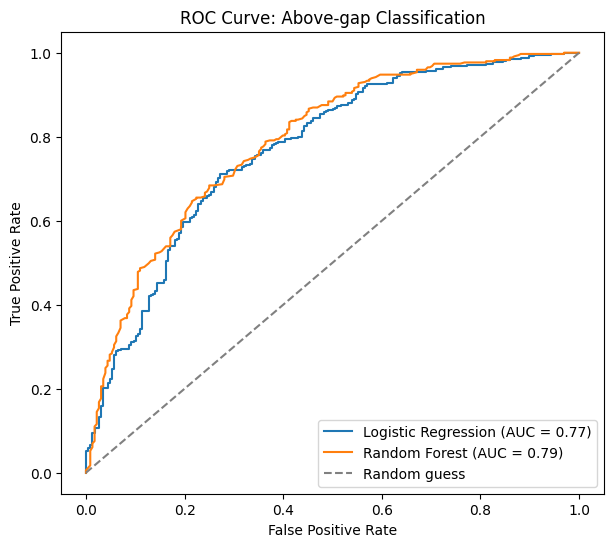

In [10]:
fpr_lr, tpr_lr, _ = roc_curve(y_test, y_proba_lr)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_proba_rf)

plt.figure(figsize=(7, 6))
plt.plot(fpr_lr, tpr_lr, label=f'Logistic Regression (AUC = {roc_auc_score(y_test, y_proba_lr):.2f})')
plt.plot(fpr_rf, tpr_rf, label=f'Random Forest (AUC = {roc_auc_score(y_test, y_proba_rf):.2f})')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Random guess')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve: Above-gap Classification')
plt.legend()
plt.show()

## Model evaluation

Both models show moderate but real ability to distinguish under-gap from above-gap planets using only orbital and stellar parameters (without direct access to radius):

- **Logistic Regression**: ROC-AUC = 0.77, well-balanced recall across both classes (0.73 for under-gap, 0.71 for above-gap) thanks to `class_weight='balanced'`.
- **Random Forest**: ROC-AUC = 0.79, a slightly higher overall score, but weaker recall for the under-gap class (0.57) — the model remains biased toward the majority class despite balancing.

A ROC-AUC of ~0.5 would indicate no predictive information (random guessing), while 1.0 would be perfect classification. The observed ~0.77-0.79 range shows a real, moderately strong signal — expected, since these predictors influence the radius indirectly (through physical processes) rather than directly.

Neither model is a clear "winner" — both show similar predictive power with a different trade-off between classes. This is itself an honest and useful finding.

In [11]:
# Logistic Regression coefficients 
coef_df = pd.DataFrame({
    'feature': X_train_scaled.columns,
    'coefficient': log_reg.coef_[0]
}).sort_values('coefficient', key=abs, ascending=False)

print("Logistic Regression coefficients:")
print(coef_df)

# Random Forest feature importance
importance_df = pd.DataFrame({
    'feature': X_train.columns,
    'importance': rf.feature_importances_
}).sort_values('importance', ascending=False)

print("\nRandom Forest feature importance:")
print(importance_df)

Logistic Regression coefficients:
     feature  coefficient
0  pl_orbper     0.692200
1   pl_insol    -0.533081
4    st_mass     0.492192
5     st_met     0.237233
7    sy_pnum    -0.201446
6    sy_dist    -0.168911
2    st_teff    -0.059042
3     st_rad     0.021112

Random Forest feature importance:
     feature  importance
0  pl_orbper    0.224138
1   pl_insol    0.179050
6    sy_dist    0.145232
2    st_teff    0.109358
3     st_rad    0.107004
5     st_met    0.101079
4    st_mass    0.098013
7    sy_pnum    0.036126


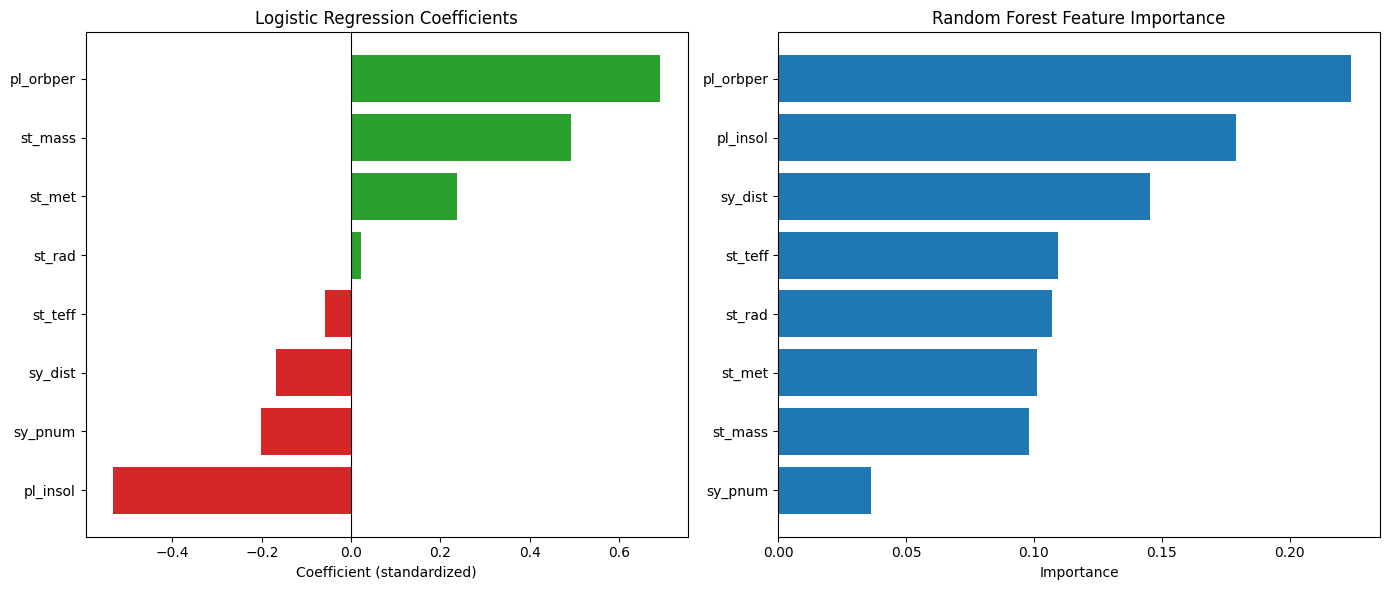

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Logistic Regression coefficients
coef_df_sorted = coef_df.sort_values('coefficient')
colors_lr = ['#d62728' if c < 0 else '#2ca02c' for c in coef_df_sorted['coefficient']]
axes[0].barh(coef_df_sorted['feature'], coef_df_sorted['coefficient'], color=colors_lr)
axes[0].axvline(0, color='black', linewidth=0.8)
axes[0].set_xlabel('Coefficient (standardized)')
axes[0].set_title('Logistic Regression Coefficients')

# Random Forest importance
importance_df_sorted = importance_df.sort_values('importance')
axes[1].barh(importance_df_sorted['feature'], importance_df_sorted['importance'], color='#1f77b4')
axes[1].set_xlabel('Importance')
axes[1].set_title('Random Forest Feature Importance')

plt.tight_layout()
plt.show()

## Predictors for classification (above/under gap)

Both models place **orbital period (pl_orbper)** and **insolation (pl_insol)** at the top. This is physically expected and connects directly to the theory from Phase 0: planets close to their star (short period, high insolation) are exposed to stronger photoevaporation and core-powered mass-loss, stripping their atmospheres and leaving them smaller (under-gap). Planets farther out retain denser atmospheres and remain larger (above-gap).

**Read these as a pair, not as a ranking.** Period and insolation are physically near-redundant (S ∝ L⋆/a², a ∝ P^2/3), correlate at r≈-0.74 on this sample, and carry variance inflation factors of 21.5 and 26.9 — far above the conventional threshold of 10. Their individual coefficients are not separately identifiable. Notebook 06 confirms the ordering is unstable: permutation importance on the held-out set puts insolation (0.094) *above* period (0.054), reversing the impurity-based ordering shown here. The defensible claim is that the period-insolation axis jointly dominates.

**st_mass** (positive coefficient) and **st_met** (positive, weaker) suggest that more massive/more metal-rich stars are associated with above-gap planets — possibly reflecting more gas-rich protoplanetary disks. Note st_mass also carries a high VIF (22.7), so the same caution applies.

**sy_pnum** (number of planets in the system) has a negative coefficient — systems with more planets tend toward smaller planets (under-gap), consistent with the "peas in a pod" effect discussed earlier. Its low random-forest importance is partly an artifact: impurity-based importance is biased toward continuous, high-cardinality predictors and understates discrete ones.

**sy_dist** (distance to the system) emerges as moderately important in both models, but this likely isn't a physical cause — rather a detection bias, since more distant systems have weaker characterization of their parameters.

**Conclusion:** Both models (ROC-AUC 0.77-0.79) show a moderate but real signal that orbital/stellar parameters partially predict a planet's position relative to the gap, with the period/insolation axis dominating. This is consistent with photoevaporation/core-powered mass-loss theory — though notebook 06 shows the same signature is also produced by transit detection bias, which this sample cannot correct for.

In [13]:
# Ambiguous zone = the UNION of the bootstrap 95% intervals across all four
# filtering variants in Phase 4 (lowest lower bound 1.62, highest upper bound 1.83).
# This is deliberately wider than the main-sample interval [1.67, 1.83], i.e. a
# more conservative robustness check.
clear_cases = complete_cases[(complete_cases['pl_rade'] < 1.62) | (complete_cases['pl_rade'] > 1.83)].copy()

print("Original complete cases:", len(complete_cases))
print("Clear cases (excluding ambiguous zone):", len(clear_cases))
print(clear_cases['above_gap'].value_counts(normalize=True))

Original complete cases: 2289
Clear cases (excluding ambiguous zone): 2089
above_gap
1    0.635711
0    0.364289
Name: proportion, dtype: float64


In [14]:
X_clear = clear_cases[predictor_cols]
y_clear = clear_cases['above_gap']

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clear, y_clear, test_size=0.25, random_state=42, stratify=y_clear
)

X_train_c_log = X_train_c.copy()
X_test_c_log = X_test_c.copy()
for col in ['pl_orbper', 'pl_insol', 'sy_dist']:
    X_train_c_log[col] = np.log10(X_train_c_log[col])
    X_test_c_log[col] = np.log10(X_test_c_log[col])

scaler_c = StandardScaler()
X_train_c_scaled = pd.DataFrame(scaler_c.fit_transform(X_train_c_log), columns=X_train_c_log.columns, index=X_train_c_log.index)
X_test_c_scaled = pd.DataFrame(scaler_c.transform(X_test_c_log), columns=X_test_c_log.columns, index=X_test_c_log.index)

print("Train:", X_train_c.shape, " Test:", X_test_c.shape)

Train: (1566, 8)  Test: (523, 8)


In [15]:
log_reg_c = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
log_reg_c.fit(X_train_c_scaled, y_train_c)
y_proba_lr_c = log_reg_c.predict_proba(X_test_c_scaled)[:, 1]

rf_c = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=42)
rf_c.fit(X_train_c, y_train_c)
y_proba_rf_c = rf_c.predict_proba(X_test_c)[:, 1]

print("Clear-cases Logistic Regression ROC-AUC:", roc_auc_score(y_test_c, y_proba_lr_c))
print("Clear-cases Random Forest ROC-AUC:", roc_auc_score(y_test_c, y_proba_rf_c))
print()
print("Original Logistic Regression ROC-AUC:", roc_auc_score(y_test, y_proba_lr))
print("Original Random Forest ROC-AUC:", roc_auc_score(y_test, y_proba_rf))

Clear-cases Logistic Regression ROC-AUC: 0.7717151327824388
Clear-cases Random Forest ROC-AUC: 0.810414432599508

Original Logistic Regression ROC-AUC: 0.7700610221205187
Original Random Forest ROC-AUC: 0.7898550724637683


## Sensitivity check: excluding the ambiguous zone

As an additional robustness check, we excluded planets falling within the union of the bootstrap 95% intervals across all four filtering variants of Phase 4 (1.62-1.83 R⊕, where 1.62 is the lowest lower bound and 1.83 the highest upper bound) — the "ambiguous zone" where class assignment is least certain — and re-trained both models on the remaining 2089 "clear" cases. This is deliberately wider than the main sample's own interval of [1.67, 1.83] R⊕, and so a more conservative check.

Results were nearly identical to the original sharp-threshold classification (Logistic Regression: 0.770 → 0.772 ROC-AUC; Random Forest: 0.790 → 0.810 ROC-AUC), confirming that the classification results are not an artifact of the specific threshold choice. If anything, Random Forest performance improved slightly with the ambiguous zone removed, consistent with boundary-adjacent planets being intrinsically harder to classify correctly.